# Google Colab Environment Setup

**Python 3.12 required.** Before running, select **Runtime > Change runtime type > Runtime Version > 2026.07**, then reconnect. Google currently lists this Python 3.12 runtime; if it is no longer offered, use **Run with Binder** on the MDAS website. The default Python 3.13 runtime is incompatible with the published KaleCancer/PyKale requirements.

Run the setup cell below, then run the scientific cells individually in order. Setup downloads the companion module and installs a pinned CPU stack in **this notebook's active Python environment**; no separate notebook, Drive mount or upload is needed. The first installation may take several minutes. If libraries with different versions are already loaded, setup will ask you to **Restart session** and rerun setup before continuing. Reruns reuse the installed packages and downloaded files.

If you ran an earlier setup in this session, restart the session after the corrected packages are installed, then rerun setup. This includes Hugging Face Hub/Transformers imports: changing packages on disk does not replace already imported modules. Continue only when **MDAS ready** prints the corrected Hub version.

Every cell below this setup section is preserved from the original MDAS notebook, including its full training and advanced analyses. Use synthetic data only. Colab sessions are temporary; download work you want to keep.


In [ ]:
# Bootstrap only: scientific code below is unchanged.
import hashlib
from pathlib import Path
import runpy
import sys
from urllib.request import Request, urlopen

if sys.version_info[:2] != (3, 12):
    raise RuntimeError("Python 3.12 is required. Choose Runtime > Change runtime type > Runtime Version > 2026.07, reconnect, then rerun setup. If unavailable, use Run with Binder.")

# Prefer a local checkout when testing; a fresh Colab session uses /content.
_candidates = [Path.cwd(), *(p / "notebooks/MDAS/cancer" for p in [Path.cwd(), *Path.cwd().parents])]
_mdas_dir = next((p for p in _candidates if (p / "colab_setup.py").is_file()), Path("/content/mdas-cancer/notebooks/MDAS/cancer"))
_mdas_dir.mkdir(parents=True, exist_ok=True)
_checksums = {'colab_setup.py': '0a9845ac9c0853140388a0908001ed63891ac7acae3a3002c23dab9f70344d00', 'colab-requirements.txt': 'f5c6948c023fe817ea38c3d535d988e3f8e0ddaa045aa37db0d2ee1bc63d946b', 'synthetic_data_generation.py': '4c599967243fb0f8f782bbcac4ae2bf3978884598ffbd54c048c87c147d89a22', 'synthetic_showcase_data.py': '52fdb92cad3dfa3781bc745234e0fcce19817d9b293d9fcfb91744162ebc5251'}
try:
    for _name, _digest in _checksums.items():
        _path = _mdas_dir / _name
        if not _path.is_file() or hashlib.sha256(_path.read_bytes().replace(b"\r\n", b"\n")).hexdigest() != _digest:
            print("MDAS: downloading", _name, flush=True)
            _url = "https://raw.githubusercontent.com/pykale/mdas/main/notebooks/MDAS/cancer/" + _name
            with urlopen(Request(_url, headers={"User-Agent": "MDAS-Colab"}), timeout=60) as _response:
                _contents = _response.read().replace(b"\r\n", b"\n")
            if hashlib.sha256(_contents).hexdigest() != _digest:
                raise RuntimeError("Setup revision mismatch. Reopen the latest Colab notebook from the MDAS website; no downloaded code was executed.")
            _temporary = _path.with_suffix(_path.suffix + ".tmp")
            _temporary.write_bytes(_contents)
            _temporary.replace(_path)
    runpy.run_path(str(_mdas_dir / "colab_setup.py"))["prepare"](_mdas_dir, showcase=True)
except OSError as _error:
    raise RuntimeError("MDAS download/install failed. Check internet access and rerun setup. The reviewed Colab support files must exist on public main.") from _error


# KaleCancer Example: Clinical covariates and WSI to predict survival

You have a clinical table, a folder of pathology slide features, and follow-up times for each patient.

In this tutorial, we will answer three questions:

1. Can these data predict who survives longer?
2. Does combining them beat using either one alone?
3. What is the model actually looking at, and what does it say about one patient?

This is the time-to-event counterpart to `classification_showcase.ipynb`. The workflow is the same, so this notebook focuses on what changes for survival.

The cohort is synthetic. We created the signal ourselves, so we can check that KaleCancer finds it. The results are purely illustrative.

In [79]:
import warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

from synthetic_showcase_data import make_showcase_cohort, PATCH_SIZE

RANDOM_STATE = 0

warnings.filterwarnings('ignore', message='IProgress not found')
LOW, HIGH, MODEL = '#2a78d6', '#eb6834', '#1baf7a'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})

## 1 Load Your Data

In [80]:
data_folder = '../../../data/synthetic_showcase_survival'
make_showcase_cohort(data_folder, task='survival')

table = pd.read_csv(data_folder + '/clinical.csv', index_col=0)
display(table.head())

,age,gender,time,event
patient_id,,,,
patient_000,63.047171,M,140.161953,True
patient_001,49.600159,F,1862.486595,True
patient_002,NaN,F,668.519881,True
patient_003,69.405647,F,11.549494,True
patient_004,NaN,F,2163.788231,False


Each patient has a `time` in days and an `event` flag. `event=True` means the event happened at that time. `event=False` means the patient was **censored**: they were still event-free when follow-up ended, so all we know is that their event comes later.

Censored patients still carry information, so we don't drop them. `TimeToEvent` keeps both columns together, and everything else about loading stays the same.

In [81]:
from kalecancer.loaddata import Tabular, PatchFeatures, TimeToEvent, MultimodalDataset

clinical = Tabular(table.drop(columns=['time', 'event']))
slides = PatchFeatures.from_glob(data_folder + '/patches/*.h5', id_pattern=r'(patient_\d{3})\.h5')
target = TimeToEvent(time=table['time'], event=table['event'])

dataset = MultimodalDataset(
    modalities={'clinical': clinical, 'slides': slides},
    target=target,
    required_modalities=[]
)
display(dataset.summary())

,count
available: clinical,200
available: slides,180
available: target,200
included,200
included with clinical,200
included with slides,180
events,114


## Visualising the data

Follow-up ends in one of two ways: an event or censoring. Patches each contain a coordinate pointing to their location on the WSI they encode.

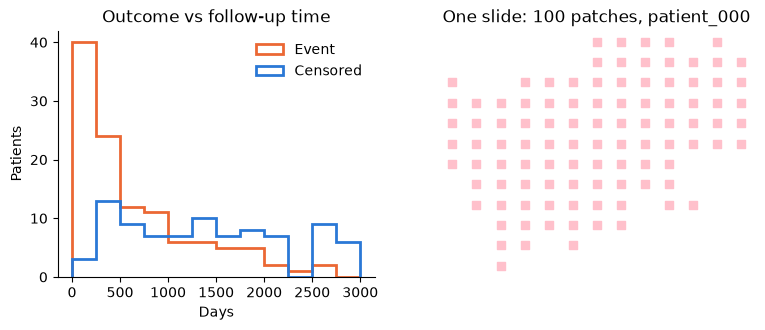

In [82]:
fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.2))

for event, label, colour in [(True, 'Event', HIGH), (False, 'Censored', LOW)]:
    left.hist(table.loc[table['event'] == event, 'time'], bins=range(0, 3250, 250), histtype='step', linewidth=2, color=colour, label=label)
left.set(title='Outcome vs follow-up time', xlabel='Days', ylabel='Patients')
left.legend(frameon=False)

patient = slides.ids[0]
patches = slides.instances(patient)
right.scatter(patches['x'], patches['y'], marker='s', s=26, color='pink')
right.set_title(f'One slide: {len(patches)} patches, {patient}')
right.axis('off')
plt.show()

## 2 Build a Model

For Intermediate Fusion: each modality gets an encoder, a fusion method combines them, and a head makes the prediction. Only the head changes from classification.

`CoxHead` predicts one number per patient, the `log_hazard`: higher means higher risk. `ties='efron'` sets how the loss handles patients with the same event time.

In [83]:
from kalecancer.model import ABMIL, MLP, IntermediateFusion, MaskedMean, CoxHead

# Needed to ensure model weights are initialised consistently
torch.manual_seed(RANDOM_STATE)

clinical_encoder = MLP(in_dim=2, hidden_dims=[16], out_dim=16, dropout=0.25)
slide_encoder = ABMIL(in_dim=32, hidden_dim=16, attention_dim=8, dropout=0.25)
head = CoxHead(in_dim=16, ties='efron')

model = IntermediateFusion(
    encoders={'clinical': [clinical_encoder], 'slides': [slide_encoder]},
    fusion=MaskedMean(),
    head=head
)

## 3 Train

`Pipeline` works just as it does for classification, with two survival choices:

- **Batch size:** the Cox loss compares each event with the patients still at risk in the same batch, so bigger batches give it more to compare. We use 32 rather than 16.
- **Early stopping:** it watches the validation loss rather than a metric like AUROC. The concordance index, `HarrellC`, only changes when two patients swap order. With few validation events, it moves in coarse steps and ties between epochs, so we use it to evaluate instead.

In [97]:
from functools import partial
from sklearn.impute import SimpleImputer
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.preprocessing import OrdinalEncoder, StandardScaler
from kalecancer.pipeline import EarlyStopping, Pipeline
from kalecancer.prepdata import ColumnGroup, TableTransform

clinical_transform = TableTransform(
    groups={
        'numeric': ColumnGroup(['age'], [SimpleImputer(), StandardScaler()]),
        'categorical': ColumnGroup(['gender'], [OrdinalEncoder(encoded_missing_value=-1)])
    },
    drop=[]
)

pipeline = Pipeline(
    model=model,
    transforms={'clinical': clinical_transform},
    optimizer=partial(torch.optim.AdamW, lr=3e-3),
    batch_size=32,
    drop_last=False,
    max_epochs=80,
    validation=StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE),
    early_stopping=EarlyStopping(metric='loss', patience=25, restore_best=True),
    accelerator='cpu',
    precision='32-true',
    random_state= RANDOM_STATE
)

Splits are stratified on `event`, so train and test keep the same share of events.

In [103]:
from kalecancer.loaddata import train_test_split

train, test = train_test_split(dataset, test_size=0.25, stratify=True, random_state=RANDOM_STATE)

pipeline.fit(train)
pipeline.fit_report_

{'n_train': 120,
 'n_val': 30,
 'events': 68,
 'epochs_run': 61,
 'best_epoch': 35,
 'best_score': 2.2644824981689453,
 'optimizer_steps': 244,
 'skipped_batches': 0,
 'non_finite_inputs': {},
 'baseline_events': 85}

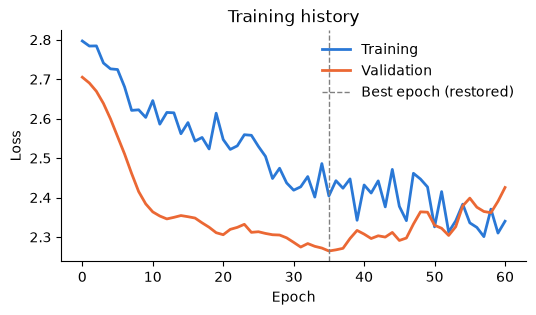

In [104]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(pipeline.history_['train_loss'], color=LOW, linewidth=2, label='Training')
ax.plot(pipeline.history_['val_loss'], color=HIGH, linewidth=2, label='Validation')
ax.axvline(pipeline.fit_report_['best_epoch'], color='grey', linestyle='--', linewidth=1, label='Best epoch (restored)')
ax.set(title='Training history', xlabel='Epoch', ylabel='Loss')
ax.legend(frameon=False)
plt.show()

## 4 Evaluate

A log-hazard only ranks patients, and its zero point is arbitrary. To turn it into survival probabilities, `fit` also estimates a baseline hazard on the training patients. Pass `survival_times` to get a `survival[<time>]` column for each time.

All patients get a prediction, even those that don't have any patches.

In [105]:
survival_times = [365 * year for year in range(1, 6)]
predictions = pipeline.predict(test, survival_times=survival_times)

no_slide = test.present.index[~test.present['slides']]
print(f'{len(no_slide)} of the {len(test)} test patients have no slide. Their predictions:')
display(predictions.loc[no_slide[:]].round(3))

2 of the 50 test patients have no slide. Their predictions:


,log_hazard,survival[365.0],survival[730.0],survival[1095.0],survival[1460.0],survival[1825.0]
id,,,,,,
patient_030,1.431,0.806,0.707,0.615,0.536,0.447
patient_145,1.428,0.806,0.708,0.616,0.537,0.448


Survival metrics answer different questions:

| Metric | Question | Reading it |
| --- | --- | --- |
| `HarrellC` | Of two patients, did the one with the earlier event have the higher risk? | 1 is perfect, 0.5 is chance |
| `UnoC` | The same, up to 5 years, weighted to correct for censoring | 1 is perfect, 0.5 is chance |
| `TimeDependentAUC` | Can it separate who had the event by 3 years from who didn't? | 1 is perfect, 0.5 is chance |
| `IntegratedBrier` | How close are the predicted probabilities to what happened? | 0 is perfect, about 0.25 is predicting 50% for everyone |
| `CalibrationError` | When we predict 70% survival, do about 70% survive? | 0 is perfect |
| `LogRank` | How far apart are the survival curves of the risk groups? | Higher is better, about 1 is chance |

The first three only rank patients, so a model can score well on them and still predict the wrong probabilities. `IntegratedBrier` and `CalibrationError` check the probabilities too.

In [107]:
from kalecancer.evaluate import CalibrationError, HarrellC, IntegratedBrier, LogRank, TimeDependentAUC, UnoC

harrell = HarrellC()

metrics = {
    'harrell_c': harrell,
    'uno_c_5y': UnoC(tau=365.0*5),
    'auc_3y': TimeDependentAUC(time=365.0*3),
    'integrated_brier': IntegratedBrier(),
    'calibration_error': CalibrationError(n_bins=3),
    'log_rank': LogRank(n_groups=2)
}

pipeline.evaluate(test, metrics, survival_times=survival_times)

harrell_c             0.797657
uno_c_5y              0.782294
auc_3y                0.851631
integrated_brier      0.181243
calibration_error     0.090533
log_rank             14.654722
Name: score, dtype: float64

A C-index can't reach 1 here, even for a perfect model. Event times are random, so a high-risk patient sometimes outlives a low-risk one. Scoring these test patients with the exact risk formula we used to create them gives about 0.79, which is about what our model scores. With only 50 patients, either one can come out slightly ahead by chance.

Evaluating on the training cohort is data leakage. KaleCancer guards against this behaviour.

In [108]:
try:
    pipeline.evaluate(train, metrics, survival_times=survival_times)
except ValueError as error:
    print(error)

150 patients were used to fit this pipeline (e.g. ['patient_001', 'patient_004', 'patient_005', 'patient_006', 'patient_007']); evaluate on held-out patients, or pass allow_seen=True


`bootstrap_ci` allows us to calculate confidence intervals instead of a single metric value.

`kaplan_meier` splits patients into risk groups by `log_hazard` and estimates each group's survival. `calibration_table` compares predicted survival with observed survival. Observed survival comes from a Kaplan-Meier estimate, so censoring is handled correctly.

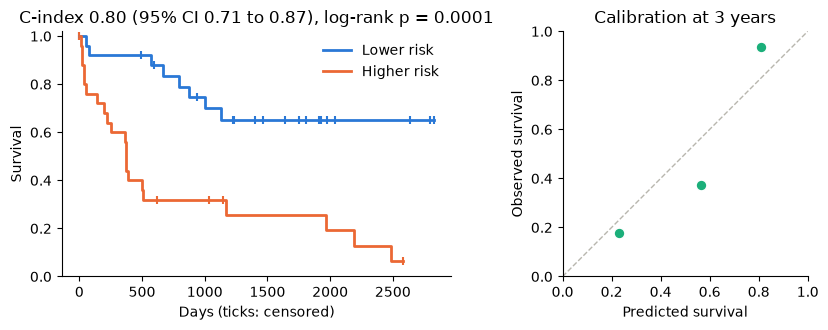

In [112]:
from scipy.stats import chi2
from kalecancer.evaluate import EvalContext, bootstrap_ci, calibration_table, kaplan_meier

truth = test.target.frame.loc[predictions.index]
context = EvalContext(train_target=pipeline.train_target_, classes=None)
interval = bootstrap_ci(harrell, predictions, truth, context)

curves = kaplan_meier(predictions, truth, n_groups=2, labels=['Lower risk', 'Higher risk'])
p_value = chi2.sf(metrics['log_rank'](predictions, truth, context), df=1)
calibration = calibration_table(predictions, truth, n_bins=3)
calibration = calibration[calibration['time'] == 1095]

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.4))

for group, colour in [('Lower risk', LOW), ('Higher risk', HIGH)]:
    curve = curves[curves['group'] == group]
    censored = curve[(curve['events'] == 0)]
    left.step(curve['time'], curve['survival'], where='post', color=colour, linewidth=2, label=group)
    left.scatter(censored['time'], censored['survival'], marker='|', s=40, color=colour)
left.set(title=f'C-index {interval.estimate:.2f} (95% CI {interval.lower:.2f} to {interval.upper:.2f}), log-rank p = {p_value:.1g}',
         xlabel='Days (ticks: censored)', ylabel='Survival', ylim=(0, 1.02))
left.legend(frameon=False)

right.plot([0, 1], [0, 1], color='#b8b6ae', linestyle='--', linewidth=1)
right.scatter(calibration['expected'], calibration['observed'], s=60, color=MODEL, edgecolor='white')
right.set(title='Calibration at 3 years', xlabel='Predicted survival', ylabel='Observed survival', xlim=(0, 1), ylim=(0, 1))
right.set_aspect('equal')
plt.tight_layout()
plt.show()

## 5 Does Combining Modalities Help?

Swapping the model takes one line, and everything else stays the same. To compare fairly, we use only patients who have both modalities, and train every candidate for the same number of epochs.

For survival, late fusion needs this anyway. Each branch's log-hazard has an arbitrary offset, so averaging different branches for different patients would reorder them. KaleCancer refuses to fit it on patients with a missing slide:

In [117]:
from sklearn.base import clone
from kalecancer.model import LateFusion, Unimodal

clinical_model = Unimodal('clinical', [clinical_encoder], head)
slide_model = Unimodal('slides', [slide_encoder], head)
late_fusion = LateFusion({'clinical': clinical_model, 'slides': slide_model}, fusion=MaskedMean())

try:
    clone(pipeline).set_params(model=late_fusion).fit(train)
except ValueError as error:
    print(error)

MaskedMean over Cox Head needs every patient to have every branch, but 18 do not: each branch's log-hazard has an arbitrary offset, so averaging different subsets of branches would reorder patients


`cross_validate` refits everything in every fold:

In [118]:
from sklearn.model_selection import StratifiedKFold
from kalecancer.evaluate import cross_validate

candidates = {
    'Clinical only': clinical_model,
    'Slides only': slide_model,
    'Late fusion': late_fusion,
    'Intermediate fusion': model
}

complete = dataset.subset(dataset.present_ids('slides'))
folds = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
fixed_training = {'validation': None, 'early_stopping': None, 'max_epochs': 40}

results = {
    name: cross_validate(clone(pipeline).set_params(model=candidate, **fixed_training), complete, folds, {'harrell_c': harrell})
    for name, candidate in candidates.items()
}

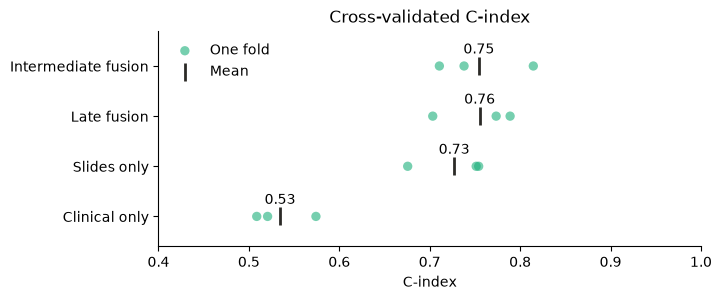

In [120]:
fig, ax = plt.subplots(figsize=(7, 2.8))
for row, (name, result) in enumerate(results.items()):
    scores = result.folds['harrell_c']
    ax.scatter(scores, [row] * len(scores), s=45, color=MODEL, alpha=0.6, edgecolor='none', label='One fold' if row == 0 else None)
    ax.scatter(scores.mean(), row, s=160, marker='|', color='#2b2a27', linewidth=2, label='Mean' if row == 0 else None)
    ax.annotate(f'{scores.mean():.2f}', (scores.mean(), row), xytext=(0, 9), textcoords='offset points', ha='center')
ax.set_yticks(range(len(results)), results.keys())
ax.set_ylim(-0.6, len(results) - 0.3)
ax.set(title='Cross-validated C-index', xlabel='C-index', xlim=(0.4, 1))
ax.legend(frameon=False, loc='upper left')
plt.show()

From the above we can see that slides do most of the predictive work.

Given a `baseline`, `bootstrap_ci` scores both models on the same resampled patients, so the interval is of the gain itself.

In [123]:
clinical_pipeline = clone(pipeline).set_params(model=clinical_model, **fixed_training).fit(train)
clinical_predictions = clinical_pipeline.predict(test)

gain = bootstrap_ci(
    harrell, predictions, truth, context,
    baseline=clinical_predictions
)
print(f'C-index gained by adding slides to the clinical table: {gain.estimate:+.2f} (95% CI {gain.lower:+.2f} to {gain.upper:+.2f})')

C-index gained by adding slides to the clinical table: +0.27 (95% CI +0.13 to +0.41)


## 6 Interpreting the results

The cohort was synthesised with these signals: slides carry the most signal, age adds some, and gender adds none.

Can the interpretation tools recover them?

### 6.1 Which modality matters?

These tools mark a modality as absent and measure what the model loses. Each modality is scored on the same patients, so the patients with no slide are left out.

In [124]:
from kalecancer.interpret import leave_one_out_ablation, modality_shapley

shapley = modality_shapley(pipeline, test, harrell)
ablation = leave_one_out_ablation(pipeline, test, harrell)

print(f"Scored on {len(test) - shapley.attrs['n_excluded']} patients")
pd.DataFrame({'Shapley value': shapley, 'C-index lost when removed': ablation}).round(3)

Scored on 48 patients


,Shapley value,C-index lost when removed
clinical,0.031,0.031
slides,0.245,0.245


Note: with two modalities, Shapley and ablation match. With three or more, Shapley also splits the credit fairly between modalities that overlap.

### 6.2 Which clinical features matter?

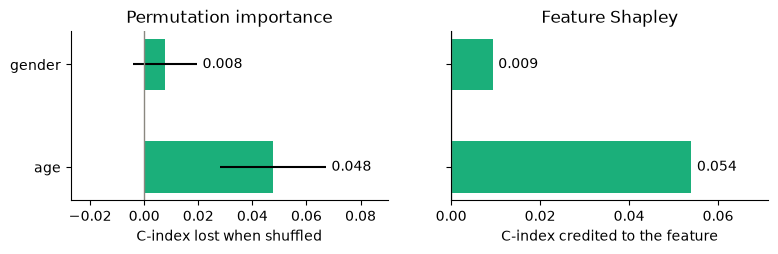

In [125]:
from kalecancer.interpret import feature_shapley, permutation_importance

importance = permutation_importance(pipeline, test, harrell, n_repeats=20, seed=RANDOM_STATE)
feature_values = feature_shapley(pipeline, test, harrell, n_samples=30, seed=RANDOM_STATE)

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 2.2), sharey=True)
left.barh(importance.index, importance['mean'], xerr=importance['std'], color=MODEL, height=0.5)
left.set(title='Permutation importance', xlabel='C-index lost when shuffled')
right.barh(feature_values.index, feature_values, color=MODEL, height=0.5)
right.set(title='Feature Shapley', xlabel='C-index credited to the feature')
for ax in (left, right):
    ax.bar_label(ax.containers[-1], fmt='%.3f', padding=4)
    ax.axvline(0, color='#8a8880', linewidth=1)
    ax.margins(x=0.32)
plt.show()

### 6.3 Where on the slide?

`attention` shows us how much weight the model gave every patch, and `attention_heatmap` helps us visualise these values.

Our synthetic data records which patches are truly aggressive, so we can compare the two.

In [126]:
import h5py
from kalecancer.interpret import attention, attention_heatmap, save_heatmap

weights = attention(pipeline, test, 'slides')

def read_aggressive(path):
    with h5py.File(path) as f:
        return f['aggressive'][:]

weights['aggressive'] = np.concatenate([read_aggressive(path) for path in weights['file'].unique()])
weights.drop(columns='file').head()

,patient_id,x,y,attention,aggressive
0,patient_000,0,1280,0.003052,False
1,patient_000,0,1536,0.005476,False
2,patient_000,0,1792,0.013401,False
3,patient_000,0,2048,0.006105,False
4,patient_000,0,2304,0.004948,False


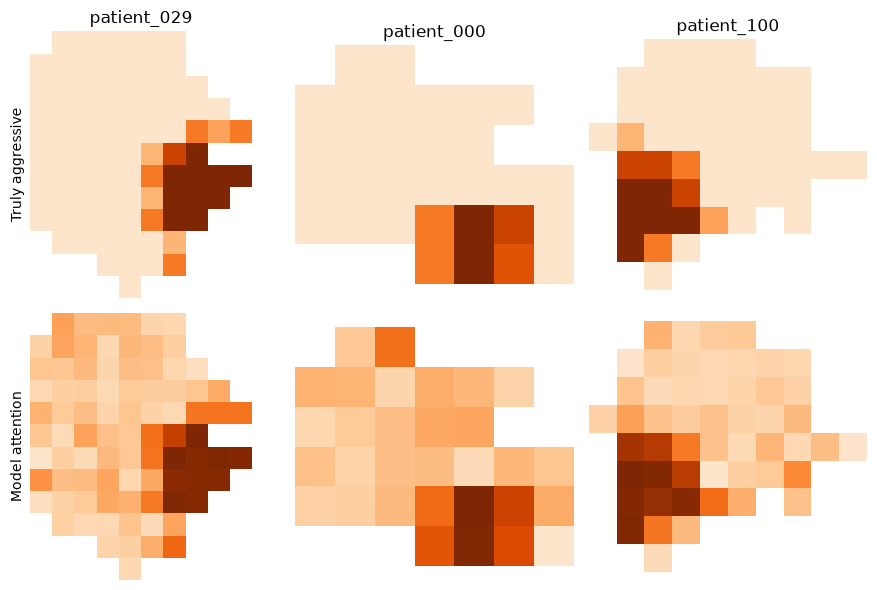

In [127]:
def heatmap(patient, column):
    rows = weights[weights['patient_id'] == patient]
    return attention_heatmap(rows, patch_size=PATCH_SIZE, downsample=2 * PATCH_SIZE, weight_column=column)

patients = predictions.loc[test.present_ids('slides'), 'log_hazard'].nlargest(3).index

fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for column, patient in enumerate(patients):
    axes[0, column].imshow(heatmap(patient, 'aggressive'), cmap='Oranges', vmin=-0.15)
    axes[0, column].set_title(patient)
    axes[1, column].imshow(heatmap(patient, 'attention'), cmap='Oranges', vmin=-0.15)
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
    ax.spines[:].set_visible(False)
axes[0, 0].set_ylabel('Truly aggressive')
axes[1, 0].set_ylabel('Model attention')
plt.tight_layout()
plt.show()

Those three are the model's highest-risk patients, so here is the check across every test slide: for each one, are the patches it attends to most actually aggressive?

In [128]:
def hit_rate(rows):
    return rows.nlargest(rows['aggressive'].sum(), 'attention')['aggressive'].mean()

with_region = weights.groupby('patient_id').filter(lambda rows: rows['aggressive'].any())
hits = with_region.groupby('patient_id')[['attention', 'aggressive']].apply(hit_rate)
chance = with_region.groupby('patient_id')['aggressive'].mean()

print(f'Most-attended patches that are truly aggressive: {hits.mean():.0%} (chance: {chance.mean():.0%}, {len(hits)} slides)')

Most-attended patches that are truly aggressive: 100% (chance: 10%, 47 slides)


Save the results to review them outside Python: a PNG for each heatmap, and a table of weights and coordinates.

In [129]:
save_heatmap(heatmap(patients[0], 'attention'), data_folder + f'/heatmaps/{patients[0]}.png', colormap='Oranges')
weights.to_csv(data_folder + '/heatmaps/attention.csv', index=False)

### 6.4 What has it learned?

`encode` gives you the embedding of any modality, ready for your own analysis. Survival has no classes to colour by, so we colour each patient by the true share of aggressive patches on their slide.

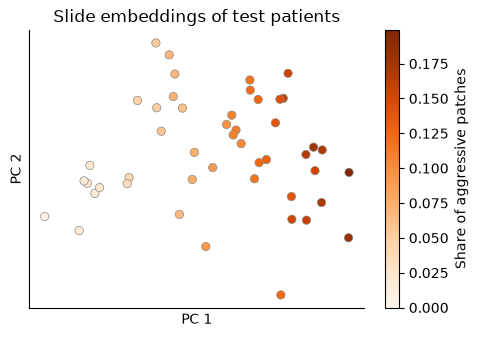

In [60]:
from sklearn.decomposition import PCA

embeddings = pipeline.encode(test, 'slides')
projection = PCA(n_components=2).fit_transform(embeddings)
aggressive_share = weights.groupby('patient_id')['aggressive'].mean().loc[embeddings.index]

fig, ax = plt.subplots(figsize=(5.4, 3.6))
points = ax.scatter(*projection.T, c=aggressive_share, cmap='Oranges', vmin=0, s=36, edgecolor='#8a8880', linewidth=0.5)
ax.set(title='Slide embeddings of test patients', xlabel='PC 1', ylabel='PC 2', xticks=[], yticks=[])
fig.colorbar(points, label='Share of aggressive patches')
plt.show()

### 6.5 What about one patient?

Everything above describes the cohort. `patient_report` explains one patient's own prediction: their risk, their survival curve, what pushed their risk up or down, and which patches mattered.

Here are the highest and lowest risk test patients who have a slide.

In [132]:
from kalecancer.interpret import patient_report, save_reports

risk = predictions.loc[test.present_ids('slides'), 'log_hazard']
highest, lowest = risk.idxmax(), risk.idxmin()

reports = patient_report(pipeline, dataset, [highest, lowest], survival_times=list(range(0, 1826, 25)), seed=RANDOM_STATE)

display(table.loc[[highest, lowest], ['age', 'gender']].round(1))
display(pd.DataFrame({
    report.patient_id: {
        'log-hazard': report.risk,
        'risk percentile': report.risk_percentile,
        **report.modality_contributions.add_prefix('modality: ').to_dict(),
        **report.feature_contributions.add_prefix('feature: ').to_dict()
    }
    for report in reports
}).round(2))

,age,gender
patient_id,,
patient_029,64.3,M
patient_058,51.3,F


,patient_029,patient_058
log-hazard,3.18,-0.01
risk percentile,98.75,7.25
modality: clinical,-1.02,1.23
modality: slides,1.02,-1.23
feature: age,0.24,-0.14
feature: gender,0.14,0.05


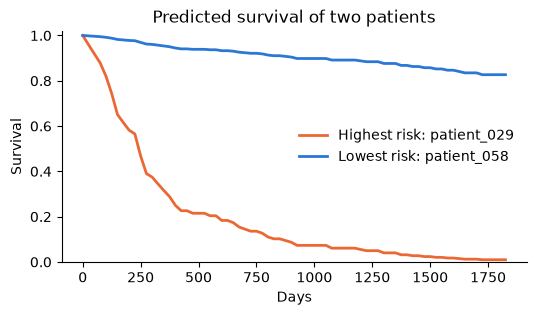

In [133]:
fig, ax = plt.subplots(figsize=(6, 3))
for report, label, colour in zip(reports, ['Highest risk', 'Lowest risk'], [HIGH, LOW], strict=True):
    ax.plot(report.survival['time'], report.survival['survival'], color=colour, linewidth=2, label=f'{label}: {report.patient_id}')
ax.set(title='Predicted survival of two patients', xlabel='Days', ylabel='Survival', ylim=(0, 1.02))
ax.legend(frameon=False)
plt.show()

These are changes in this patient's own log-hazard, not the cohort-level scores from 6.1 and 6.2.

Each report also lists the patient's most-attended patches, so you can find them on the slide:

In [63]:
display(reports[0].top_patches.drop(columns='file').head(3))
save_reports(reports, data_folder + '/patient_reports.json')

,x,y,attention
0,3072,2816,0.009703
1,3072,3584,0.009668
2,3072,3072,0.009658


## 7 Share It

`dump_config` writes the whole experiment to a YAML file. Anyone can rebuild and retrain it from that file alone, without any of the code above.

In [134]:
import yaml
from pathlib import Path
from kalecancer.pipeline import dump_config, load_pipeline

config_path = Path(data_folder) / 'pipeline.yaml'
config_path.write_text(yaml.safe_dump(dump_config(pipeline), sort_keys=False))

print(*config_path.read_text().splitlines()[:14], '...', sep='\n')

class_path: kalecancer.pipeline.Pipeline
init_args:
  model:
    class_path: kalecancer.model.IntermediateFusion
    init_args:
      encoders:
        clinical:
        - class_path: kalecancer.model.MLP
          init_args:
            in_dim: 2
            hidden_dims:
            - 16
            out_dim: 16
            dropout: 0.25
...


In [135]:
rebuilt = load_pipeline(config_path).fit(train)

print('Same predictions as the original:', np.allclose(rebuilt.predict(test, survival_times=survival_times), predictions, atol=1e-4))

Same predictions as the original: True


## KaleCancer Workflow

| You want to | Use |
| --- | --- |
| Join a table and slides by patient | `Tabular`, `PatchFeatures`, `TimeToEvent`, `MultimodalDataset` |
| Prepare data | `TableTransform`, `Pipeline` |
| Try different models | `Unimodal`, `IntermediateFusion`, `LateFusion`, `MaskedMean`, `CoxHead` |
| Measure ranking | `HarrellC`, `UnoC`, `TimeDependentAUC` |
| Measure predicted probabilities | `IntegratedBrier`, `CalibrationError`, `calibration_table` |
| Compare risk groups | `kaplan_meier`, `risk_groups`, `LogRank` |
| Get confident estimates | `cross_validate`, `bootstrap_ci`, `Pipeline.evaluate` |
| Explain modalities and features | `modality_shapley`, `leave_one_out_ablation`, `permutation_importance`, `feature_shapley` |
| Interpret slides | `attention`, `attention_heatmap`, `save_heatmap`, `Pipeline.encode` |
| Explain one patient | `patient_report`, `save_reports` |
| Share the experiment | `dump_config`, `load_pipeline` |

There is more beyond this notebook:

- **Classification outcomes:** `ClassificationHead`, `AUROC` and `BalancedAccuracy`, in `classification_showcase.ipynb`.
- **Real slides:** `overlay_on_slide` draws a heatmap on the slide image.
- **Larger clinical tables:** `TabICLEncoder` is a pretrained tabular encoder.